# 09. Replication on the 2026-27 season

**Question.** Do the 2025-26 findings hold in new data? Three checks on the start of the 2026-27 season: calibration at tipoff, the popularity effect, and the opposite trading rule that the 2025-26 results suggested.

**Plan.** This notebook follows `ANALYSIS_PLAN.md` section 10.6, which was committed before any result here was computed. All tests are two-sided at the 0.05 level.

**Data.** `data/processed/snapshots_2026_27.csv` and `data/processed/game_map_2026_27.csv`, built by the same pipeline as 2025-26 (`--season 2026-27`), and `data/processed/snapshots.csv` for each team's 2025-26 volume. The 2026-27 data was pulled once, on November 23, 2026, and is frozen at git tag `data-v2`.

**Seed.** The bootstrap uses seed 4981 and 2,000 replicates, as in the plan.

**Primary tests.** The LR test of calibration (section 2), c = 0 in the popularity model (section 3) and the return of the opposite rule against zero (section 4). They are three of the 8 primary tests of Stage 10. Their Holm adjusted p values are in `results/stage10_all_tests.csv`, written by notebook 10.

**The sample is small.** It is about one month of games. Section 5 shows how wide the intervals are next to those of the full 2025-26 season.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
from IPython.display import display

import all_tests
import calibration
import popularity
import replication as rep
from csv_io import write_csv
from stats_tools import B, SEED

rep.RESULTS_DIR.mkdir(exist_ok=True)
print(f"Bootstrap: B = {B:,}, seed = {SEED}")

Bootstrap: B = 2,000, seed = 4981


## 1. Sample

Every 2026-27 regular-season game that was final, with a settled Kalshi market, up to the cutoff date. The cutoff is the last game date before the day of the pull on which every game was final and settled. The matching rules, cleaning and flags are those of 2025-26.

In [2]:
data = rep.load()
d, threshold = data["sample"], data["threshold"]
write_csv(data["counts"], rep.RESULTS_DIR / "replication_sample_counts.csv")
display(data["counts"])
print(f"{len(d):,} games, {d['game_date'].nunique()} game dates, "
      f"{d['home_team'].nunique()} home teams, home-win rate {d['home_win'].mean():.3f}")

,group,count,first_game_date,cutoff_date
0,final regular-season games up to the cutoff date,248,2026-10-20,2026-11-22
1,matched to a settled Kalshi event,248,2026-10-20,2026-11-22
2,"main sample (matched, not postponed_window)",248,2026-10-20,2026-11-22
3,main sample games with p_home missing at tipof...,0,2026-10-20,2026-11-22
4,games in the analysis,248,2026-10-20,2026-11-22
5,game dates in the analysis,33,2026-10-20,2026-11-22


248 games, 33 game dates, 30 home teams, home-win rate 0.520


The sample is 248 games on 33 game dates, from October 20 to November 22, 2026. The data was pulled on November 23, so November 22 is the last date before the pull on which every game was final and settled.

- Every one of the 248 games matched a settled Kalshi market, and Kalshi's settlement agrees with the NBA result in all of them.
- No game is flagged `postponed_window`, and none lacks a tipoff price. Two games are flagged `tipoff_moved` and stay in, as in 2025-26.
- The home team won 52.0% of the games.

This is one fifth of the size of the 2025-26 sample (1,229 games).

## 2. Calibration at tipoff

The Stage 8 tests on the new games: the Brier score against a constant forecast, the recalibration fit logit P(home win) = a + b · logit(p) with standard errors clustered by home team, and the LR test of a = 0 and b = 1. **The LR test is the primary test.** The plot uses 5 equal-count bins, because the sample is small.

In [3]:
cal = rep.calibration_tables(d)
write_csv(cal["brier"], rep.RESULTS_DIR / "replication_brier.csv")
write_csv(cal["logistic"], rep.RESULTS_DIR / "replication_logistic.csv")
write_csv(cal["lr"], rep.RESULTS_DIR / "replication_lr_test.csv")
write_csv(cal["bootstrap"], rep.RESULTS_DIR / "replication_bootstrap.csv")
write_csv(cal["bins"], rep.RESULTS_DIR / "replication_calibration_bins.csv")
print("bootstrap replicates with a fitted model:",
      int(cal["bootstrap"].set_index("statistic").loc["slope_b", "B"]), "of", B)
display(cal["brier"].round(4))
display(cal["logistic"].round(4))
display(cal["lr"].round(4))
display(cal["bootstrap"].iloc[:7][["statistic", "estimate", "boot_lo", "boot_hi"]].round(4))

bootstrap replicates with a fitted model: 2000 of 2000


,n,home_win_rate,brier,brier_baseline,brier_diff,brier_skill
0,248,0.5202,0.1933,0.2496,-0.0563,0.2256


,term,estimate,se_cluster,ci_lo,ci_hi,null_value,z,p_value,n,n_clusters,boot_lo,boot_hi
0,intercept_a,-0.1333,0.1468,-0.4210,0.1543,0.0,-0.9084,0.3637,248,30,-0.4640,0.2226
1,slope_b,1.2467,0.1294,0.9931,1.5002,1.0,1.9068,0.0565,248,30,0.9156,1.7180


,ll_restricted,ll_unrestricted,lr_stat,df,p_value
0,-140.7353,-139.5622,2.3461,2,0.3094


,statistic,estimate,boot_lo,boot_hi
0,brier,0.1933,0.1718,0.2135
1,brier_baseline,0.2496,0.2421,0.2500
2,brier_diff,-0.0563,-0.0771,-0.0343
3,brier_skill,0.2256,0.1381,0.3095
4,intercept_a,-0.1333,-0.4640,0.2226
5,slope_b,1.2467,0.9156,1.7180
6,lr_stat,2.3461,0.1613,15.0539


,bin,n,p_min,p_max,mean_p,home_wins,win_rate,wilson_lo,wilson_hi,boot_lo,boot_hi
0,1,50,0.095,0.345,0.237,9,0.180,0.098,0.308,0.070,0.316
1,2,50,0.345,0.477,0.416,19,0.380,0.259,0.518,0.246,0.512
2,3,49,0.480,0.615,0.559,26,0.531,0.394,0.663,0.410,0.667
3,4,50,0.615,0.725,0.670,32,0.640,0.501,0.759,0.509,0.788
4,5,49,0.725,0.925,0.820,43,0.878,0.758,0.943,0.771,0.966


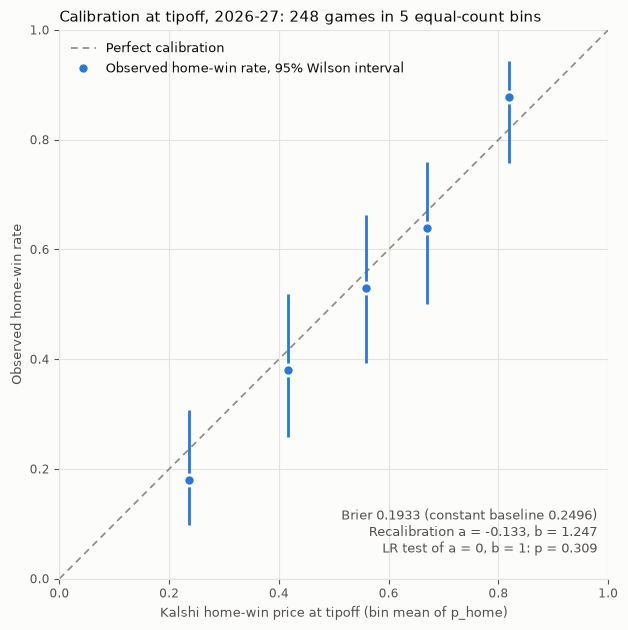

In [4]:
display(cal["bins"].round(3))
fig = calibration.calibration_plot(
    cal["bins"], cal["brier"].iloc[0], cal["lr"].iloc[0], cal["logistic"],
    rep.RESULTS_DIR / "replication_calibration_plot.png",
    title=f"Calibration at tipoff, 2026-27: {len(d):,} games in 5 equal-count bins")

**LR test (primary).** LR = 2.35 on 2 degrees of freedom, p = 0.31. The test does not reject a = 0 and b = 1: taken as they are, the tipoff prices fit the outcomes about as well as the best recalibrated version of them.

**Brier score.** 0.1933, against 0.2496 for the constant forecast. The difference is -0.0563 (bootstrap -0.077 to -0.034), and the skill score is 0.23. The prices are informative, as in 2025-26 (skill 0.21 at tipoff over the full season).

**a and b.** a = -0.133 (SE 0.147, p = 0.36). b = 1.247 (SE 0.129, p = 0.057), with clustered interval 0.993 to 1.500 and bootstrap interval 0.916 to 1.718. The slope estimate is above 1, the direction of prices that are not extreme enough, and close to the late half of 2025-26 (1.26). At this sample size it is not distinguishable from 1.

**Plot.** In all five bins the Wilson interval contains the bin's mean price.

## 3. Popularity

A team's popularity is its 2025-26 season-average pregame volume (plan section 4). It was known before the 2026-27 season began, so nothing from the new season enters it. For each game,

gap = log(home team's measure) − log(away team's measure),

and the model is that of notebook 03:

logit P(home win) = a + b · logit(p) + c · gap.

**The test is c = 0.** In 2025-26 the planned test gave c = 0.611 (more popular teams won more often than priced), and the past-games-only check gave c = 0.229.

In [5]:
pop = popularity.analyze_measure(d, rep.MEASURE)
write_csv(pop["logistic"], rep.RESULTS_DIR / "replication_popularity_logistic.csv")
write_csv(pop["effects"], rep.RESULTS_DIR / "replication_popularity_effects.csv")
write_csv(pop["bootstrap"], rep.RESULTS_DIR / "replication_popularity_bootstrap.csv")
display(d[[rep.GAP_COL]].describe().T.round(3))
display(pop["logistic"].round(4))
display(pop["effects"].round(4))

,count,mean,std,min,25%,50%,75%,max
gap_volume_2025_26,248.0,-0.003,0.512,-1.132,-0.346,-0.006,0.316,1.31


,measure,term,estimate,se_cluster,ci_lo,ci_hi,null_value,z,p_value,n,n_clusters,boot_lo,boot_hi
0,volume_2025_26,intercept_a,-0.1165,0.1485,-0.4075,0.1745,0.0,-0.7845,0.4327,248,30,-0.4618,0.2532
1,volume_2025_26,slope_b,1.1712,0.1688,0.8405,1.5020,1.0,1.0146,0.3103,248,30,0.7914,1.6553
2,volume_2025_26,gap_c,0.2451,0.2751,-0.2941,0.7842,0.0,0.8909,0.3730,248,30,-0.3901,0.9046


,measure,gap_sd,gap_c,c_per_sd,c_per_sd_boot_lo,c_per_sd_boot_hi,avg_effect_per_sd,avg_effect_boot_lo,avg_effect_boot_hi
0,volume_2025_26,0.5124,0.2451,0.1256,-0.1999,0.4635,0.0239,-0.0374,0.0817


**c.** The estimate is c = 0.245, with clustered SE 0.275 (z = 0.89, p = 0.37). The clustered 95% interval is -0.294 to 0.784 and the bootstrap interval is -0.390 to 0.905. Both contain 0.

**In plain terms.** One standard deviation of the gap is 0.51, a volume ratio of about 1.7 between the two teams. A gap one SD larger adds 0.126 to the log odds of a home win (bootstrap -0.200 to 0.464). On average that is 2.4 percentage points of win probability at the same price (bootstrap -3.7 to 8.2 points).

**Against 2025-26.** The sign is the same as in 2025-26, and the size is close to the past-games-only estimate there (0.229). But the interval is wide. It contains 0, and it also contains the 0.611 of the planned 2025-26 test. The new data neither confirm the 2025-26 effect nor rule it out.

## 4. The opposite rule

The 2025-26 results suggested that the more popular team was underpriced. Testing that on 2025-26 itself would not be a fair test. This is the fair one: the rule was written down before any 2026-27 result was seen, and everything it uses comes from 2025-26.

- **Threshold.** The 75th percentile of |gap| over the 1,229 games of the 2025-26 main sample, with the same measure.
- **Rule.** In every 2026-27 game with |gap| at or above the threshold, stake $100 on the more popular team at its tipoff ask. Contracts = floor(100 / ask).
- **Fee.** Kalshi's taker fee as in notebook 05: 0.07 · C · P · (1 − P), rounded up to the next cent, once per order. The fee fields of the series were checked again on November 23, 2026.
- **Benchmark (secondary).** The same stake on the more popular team in every game.

**The primary test is the rule's return per dollar staked against zero**, with the block bootstrap by game date.

In [6]:
rule = rep.opposite_rule(d, threshold)
write_csv(rule["results"], rep.RESULTS_DIR / "replication_opposite_rule.csv")
write_csv(rule["trades"], rep.RESULTS_DIR / "replication_opposite_trades.csv")
print(f"Threshold from 2025-26: |gap| >= {threshold:.4f} "
      f"(a volume ratio of {np.exp(threshold):.2f})")
display(rule["results"].set_index("strategy").T)

Threshold from 2025-26: |gap| >= 0.5630 (a volume ratio of 1.76)


strategy,opposite_rule,opposite_benchmark
threshold,0.563034,NaN
tradable_games,248.000000,248.000000
signals,72.000000,248.000000
no_trade_bad_ask,0.000000,0.000000
no_trade_gap_zero,0.000000,0.000000
n_trades,72.000000,248.000000
wins,58.000000,145.000000
win_rate,0.805556,0.584677
mean_ask,0.711250,0.603427
contracts,10683.000000,47144.000000


**The rule (primary).** The threshold from 2025-26 is a gap of 0.563, a volume ratio of 1.76. It selected 72 of the 248 games (29%).

- The team bought won 58 of the 72 games (80.6%). The average ask paid was 0.711, so prices implied about 51 wins.
- Cost $7,171.80, fees $145.31, profit +$684.89.
- Return per dollar staked: +9.4%. The bootstrap interval is -2.7% to +20.3%, and the bootstrap p value is 0.12. The interval for profit is -$173 to +$1,555.
- Before fees: profit +$830.20, return +11.6%.

The return is positive, the direction the 2025-26 results suggested, but it is not distinguishable from 0. Seventy-two trades on 33 dates is little to go on.

**The benchmark (secondary).** Buying the more popular team in all 248 games lost money: 145 wins (58.5%) at an average ask of 0.603, profit -$2,461.34, return -9.7% (bootstrap -19.3% to -1.1%, p = 0.031, not adjusted). Before fees the return is -7.2%.

**What the numbers show.** In this month, being the more popular team was not enough to be a good buy. The rule's profit comes from the games with a large gap only. With one month of data, neither number says what a full season would give.

No game had a missing or unusable ask, and no game had a gap of exactly 0.

## 5. How much the sample can tell

The width of the 95% interval for the calibration slope b, next to the same numbers for the full 2025-26 season.

In [7]:
width = pd.DataFrame([rep.slope_width(cal["logistic"], "2026-27"),
                      rep.slope_width(rep.previous_slope(), "2025-26")])
write_csv(width, rep.RESULTS_DIR / "replication_slope_width.csv")
display(width.round(4))

,season,n,slope_b,se_cluster,ci_lo,ci_hi,ci_width,boot_lo,boot_hi,boot_width
0,2026-27,248,1.2467,0.1294,0.9931,1.5002,0.5071,0.9156,1.7180,0.8024
1,2025-26,1229,1.0352,0.0616,0.9144,1.1559,0.2414,0.9079,1.1817,0.2737


The 95% interval for the slope is about 0.51 wide in 2026-27 (clustered), against 0.24 in 2025-26. The bootstrap interval is 0.80 wide, against 0.27. So the new sample pins the slope down two to three times less tightly: any slope from about 0.9 to 1.7 is compatible with it.

This is the main limit of the whole notebook. A test that does not reject here says little, because the sample could not have detected a moderate departure from calibration.

## 6. All tests of this notebook

Every test above in the common Stage 10 layout. `p_bound` is min(1, 8 · p) for the primary tests: the Holm adjusted p value across the 8 primary tests of Stage 10 can never be above it. The Holm values themselves are added by notebook 10.

In [8]:
tests = rep.tests_table(cal, pop, rule)
write_csv(tests, all_tests.part_path(rep.PART))
shown = tests[["test_id", "role", "n", "unit", "estimate", "ci_lo", "ci_hi", "statistic",
               "p_raw"]].copy()
shown["p_bound"] = all_tests.bonferroni_bound(shown["p_raw"]).where(shown["role"] == "primary")
display(shown.round(4))

,test_id,role,n,unit,estimate,ci_lo,ci_hi,statistic,p_raw,p_bound
0,replication_lr,primary,248,games,NaN,NaN,NaN,2.3461,0.3094,1.0000
1,replication_calibration_a,secondary,248,games,-0.1333,-0.4210,0.1543,-0.9084,0.3637,NaN
2,replication_calibration_b,secondary,248,games,1.2467,0.9931,1.5002,1.9068,0.0565,NaN
3,replication_brier_diff,secondary,248,games,-0.0563,-0.0771,-0.0343,NaN,0.0010,NaN
4,replication_popularity_a,secondary,248,games,-0.1165,-0.4075,0.1745,-0.7845,0.4327,NaN
5,replication_popularity_b,secondary,248,games,1.1712,0.8405,1.5020,1.0146,0.3103,NaN
6,replication_popularity_c,primary,248,games,0.2451,-0.2941,0.7842,0.8909,0.3730,1.0000
7,replication_opposite_return,primary,72,trades,0.0936,-0.0268,0.2031,NaN,0.1219,0.9755
8,replication_opposite_benchmark_return,secondary,248,trades,-0.0969,-0.1933,-0.0109,NaN,0.0310,NaN


**Primary tests.**
- Calibration LR test: p = 0.309. The bound 8 · p is 1. Not significant.
- Popularity c: p = 0.373. The bound 8 · p is 1. Not significant.
- Opposite rule return: p = 0.122. The bound 8 · p is 0.97. Not significant.

**Secondary tests.** Two of the six have a p value below 0.05, with no adjustment: the Brier score against the constant baseline (0.001), which says the prices are informative, and the benchmark return (0.031).

**In short.** The first month of 2026-27 does not contradict 2025-26. Prices are again informative and close to calibrated, the popularity effect has the same sign, and the opposite rule made money. None of the three primary tests is significant, and the sample is too small to confirm any of the three.